In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [ ]:
wine = load_wine()

df1 = pd.DataFrame(wine.data, columns=wine.feature_names)
df1["target"] = wine.target

df1.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [ ]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [ ]:
df1.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


In [ ]:
df1.isnull().sum()

,0
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


In [ ]:
df1.duplicated().sum()

np.int64(0)

In [ ]:
df1.dtypes

,0
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


In [ ]:
df1 = df1.drop_duplicates()
df1 = df1.fillna(df1.median())
df1["target"].value_counts()

,count
target,
1,71
0,59
2,48


In [ ]:
X1 = df1.drop("target", axis=1)
y1 = df1["target"]
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42, stratify=y1
)
scaler1 = StandardScaler()

X1_train_scaled = scaler1.fit_transform(X1_train)
X1_test_scaled = scaler1.transform(X1_test)

In [ ]:
model1 = LogisticRegression(max_iter=1000)

model1.fit(X1_train_scaled, y1_train)

LogisticRegression(max_iter=1000)

In [ ]:
y1_pred = model1.predict(X1_test_scaled)

y1_pred[:10]

array([0, 1, 0, 1, 1, 0, 0, 1, 1, 2])

In [ ]:
print("WINE CLASSIFICATION RESULTS")
print("=" * 35)
print(f"Model Accuracy  : {accuracy_score(y1_test, y1_pred):.2%}")
print(f"Precision       : {precision_score(y1_test, y1_pred, average='weighted'):.3f}")
print(f"Recall          : {recall_score(y1_test, y1_pred, average='weighted'):.3f}")
print(f"F1 Score        : {f1_score(y1_test, y1_pred, average='weighted'):.3f}")

WINE CLASSIFICATION RESULTS
Model Accuracy  : 97.22%
Precision       : 0.974
Recall          : 0.972
F1 Score        : 0.972


In [ ]:
print(classification_report(y1_test, y1_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



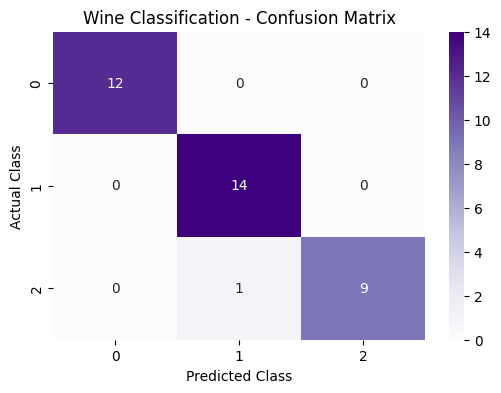

In [ ]:
cm1 = confusion_matrix(y1_test, y1_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm1, annot=True, fmt="d", cmap="Purples")

plt.title("Wine Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [ ]:
iris = load_iris()

df2 = pd.DataFrame(iris.data, columns=iris.feature_names)
df2["target"] = iris.target

df2.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [ ]:
df2.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [ ]:
df2.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0


In [ ]:
df2.duplicated().sum()

np.int64(1)

In [ ]:
df2.dtypes

,0
sepal length (cm),float64
sepal width (cm),float64
petal length (cm),float64
petal width (cm),float64
target,int64


In [ ]:
df2 = df2.drop_duplicates()
df2 = df2.fillna(df2.median())
df2["target"].value_counts()

,count
target,
0,50
1,50
2,49


In [ ]:
X2 = df2.drop("target", axis=1)
y2 = df2["target"]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2,
    test_size=0.2,
    random_state=21,
    stratify=y2
)
scaler2 = StandardScaler()

X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

In [ ]:
model2 = LogisticRegression(max_iter=1000)

model2.fit(X2_train_scaled, y2_train)

LogisticRegression(max_iter=1000)

In [ ]:
y2_pred = model2.predict(X2_test_scaled)

print("Predicted Flower Classes:")
print(y2_pred[:10])

Predicted Flower Classes:
[1 0 0 1 2 2 0 1 0 2]


In [ ]:
print("IRIS CLASSIFICATION PERFORMANCE")
print("-" * 40)

print(f"Accuracy Score : {accuracy_score(y2_test, y2_pred) * 100:.2f}%")
print(f"Precision      : {precision_score(y2_test, y2_pred, average='macro'):.3f}")
print(f"Recall         : {recall_score(y2_test, y2_pred, average='macro'):.3f}")
print(f"F1 Score       : {f1_score(y2_test, y2_pred, average='macro'):.3f}")

IRIS CLASSIFICATION PERFORMANCE
----------------------------------------
Accuracy Score : 96.67%
Precision      : 0.970
Recall         : 0.967
F1 Score       : 0.967


In [ ]:
print(classification_report(
    y2_test,
    y2_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



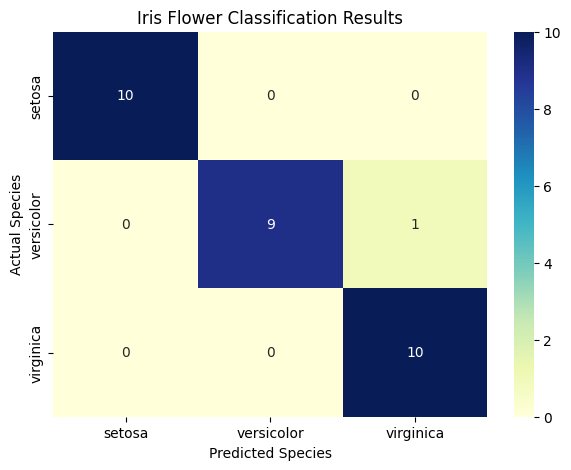

In [ ]:
cm2 = confusion_matrix(y2_test, y2_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm2,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Iris Flower Classification Results")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [ ]:
sample_flower = pd.DataFrame([[
    5.1, 3.5, 1.4, 0.2
]], columns=X2.columns)

sample_scaled = scaler2.transform(sample_flower)

prediction = model2.predict(sample_scaled)[0]

print("Predicted Flower:", iris.target_names[prediction])

Predicted Flower: setosa


In [ ]:
!pip install gradio -q

In [ ]:
import gradio as gr

def predict_wine(*values):
    data = pd.DataFrame([values], columns=X1.columns)
    scaled_data = scaler1.transform(data)

    prediction = int(model1.predict(scaled_data)[0])
    probabilities = model1.predict_proba(scaled_data)[0]

    return {
        wine.target_names[i]: float(probabilities[i])
        for i in range(len(wine.target_names))
    }


def predict_iris(sepal_length, sepal_width, petal_length, petal_width):
    data = pd.DataFrame(
        [[sepal_length, sepal_width, petal_length, petal_width]],
        columns=X2.columns
    )

    scaled_data = scaler2.transform(data)
    probabilities = model2.predict_proba(scaled_data)[0]

    return {
        iris.target_names[i]: float(probabilities[i])
        for i in range(len(iris.target_names))
    }

In [ ]:
with gr.Blocks(
    title="ClassifyAI",
    theme=gr.themes.Soft(
        primary_hue="violet",
        secondary_hue="pink"
    )
) as demo:

    gr.Markdown("""
    # ClassifyAI
    ### Intelligent Classification Studio

    Predict wine categories and iris flower species
    using Machine Learning and Logistic Regression.
    """)

    with gr.Tabs():

        # WINE CLASSIFICATION
        with gr.Tab("Wine Classification"):

            gr.Markdown("## Wine Category Predictor")
            gr.Markdown(
                "Enter the chemical properties of a wine sample."
            )

            wine_inputs = []

            with gr.Row():

                with gr.Column():
                    for feature in X1.columns[:7]:
                        inp = gr.Number(
                            label=feature.replace("_", " ").title(),
                            value=float(X1[feature].median())
                        )
                        wine_inputs.append(inp)

                with gr.Column():
                    for feature in X1.columns[7:]:
                        inp = gr.Number(
                            label=feature.replace("_", " ").title(),
                            value=float(X1[feature].median())
                        )
                        wine_inputs.append(inp)

            wine_button = gr.Button(
                "Classify Wine",
                variant="primary"
            )

            wine_output = gr.Label(
                label="Wine Classification Result",
                num_top_classes=3
            )

            wine_button.click(
                fn=predict_wine,
                inputs=wine_inputs,
                outputs=wine_output
            )

        # IRIS CLASSIFICATION
        with gr.Tab("Iris Flower Classification"):

            gr.Markdown("## Iris Species Predictor")
            gr.Markdown(
                "Enter the flower measurements in centimeters."
            )

            with gr.Row():

                with gr.Column():

                    sepal_length = gr.Slider(
                        4, 8, value=5.8,
                        label="Sepal Length (cm)"
                    )

                    sepal_width = gr.Slider(
                        2, 4.5, value=3.0,
                        label="Sepal Width (cm)"
                    )

                with gr.Column():

                    petal_length = gr.Slider(
                        1, 7, value=4.3,
                        label="Petal Length (cm)"
                    )

                    petal_width = gr.Slider(
                        0.1, 2.5, value=1.3,
                        label="Petal Width (cm)"
                    )

            iris_button = gr.Button(
                "Identify Flower",
                variant="primary"
            )

            iris_output = gr.Label(
                label="Predicted Iris Species",
                num_top_classes=3
            )

            iris_button.click(
                fn=predict_iris,
                inputs=[
                    sepal_length,
                    sepal_width,
                    petal_length,
                    petal_width
                ],
                outputs=iris_output
            )

    gr.Markdown(
        "---\n"
        "ClassifyAI | ANN Lab Task 2 | Logistic Regression"
    )

demo.launch(share=True)

/tmp/ipykernel_816/195780511.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://21193404cb320ff059.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!pip install flask pyngrok -q
from flask import Flask, request, render_template_string
from threading import Thread
import pandas as pd

app = Flask(__name__)

html = """
<!DOCTYPE html>
<html>
<head>
    <title>ClassifyAI Studio</title>
    <meta name="viewport" content="width=device-width, initial-scale=1">

    <style>
        * {
            box-sizing: border-box;
        }

        body {
            margin: 0;
            font-family: Arial, sans-serif;
            background: #f5f3ff;
            color: #1e1b4b;
        }

        .sidebar {
            width: 240px;
            height: 100vh;
            position: fixed;
            background: #1e1b4b;
            color: white;
            padding: 30px 20px;
        }

        .sidebar h2 {
            color: #c4b5fd;
            margin-bottom: 40px;
        }

        .sidebar a {
            display: block;
            color: #ddd6fe;
            text-decoration: none;
            padding: 15px;
            margin-bottom: 12px;
            border-radius: 10px;
        }

        .sidebar a:hover {
            background: #4338ca;
            color: white;
        }

        .main {
            margin-left: 240px;
            padding: 40px;
        }

        .card {
            background: white;
            border-radius: 18px;
            padding: 30px;
            max-width: 850px;
            box-shadow: 0 8px 25px rgba(0,0,0,0.07);
        }

        h1 {
            color: #312e81;
        }

        .subtitle {
            color: #64748b;
            margin-bottom: 30px;
        }

        .grid {
            display: grid;
            grid-template-columns: 1fr 1fr;
            gap: 18px;
        }

        label {
            display: block;
            font-weight: bold;
            margin-bottom: 7px;
            font-size: 14px;
        }

        input {
            width: 100%;
            padding: 12px;
            border: 1px solid #cbd5e1;
            border-radius: 8px;
        }

        button {
            background: #7c3aed;
            color: white;
            border: none;
            padding: 14px 28px;
            border-radius: 10px;
            margin-top: 25px;
            font-size: 16px;
            cursor: pointer;
        }

        button:hover {
            background: #6d28d9;
        }

        .result {
            background: #ede9fe;
            border-left: 5px solid #7c3aed;
            padding: 20px;
            margin-top: 25px;
            border-radius: 10px;
        }

        .footer {
            margin-top: 35px;
            color: #94a3b8;
            font-size: 13px;
        }

        @media (max-width: 700px) {
            .sidebar {
                position: static;
                width: 100%;
                height: auto;
            }

            .main {
                margin-left: 0;
                padding: 20px;
            }

            .grid {
                grid-template-columns: 1fr;
            }
        }
    </style>
</head>

<body>

<div class="sidebar">
    <h2>ClassifyAI</h2>

    <a href="/?page=wine">Wine Classification</a>
    <a href="/?page=iris">Iris Classification</a>
</div>

<div class="main">

    <h1>{{ title }}</h1>
    <p class="subtitle">{{ description }}</p>

    <div class="card">

        <form method="POST">

            <input type="hidden" name="page" value="{{ page }}">

            <div class="grid">

                {% for feature, value in features %}

                <div>
                    <label>{{ feature }}</label>

                    <input
                        type="number"
                        step="any"
                        name="{{ feature }}"
                        value="{{ value }}"
                        required
                    >
                </div>

                {% endfor %}

            </div>

            <button type="submit">Predict Classification</button>

        </form>

        {% if result %}

        <div class="result">
            <h3>Prediction Result</h3>
            <h2>{{ result }}</h2>
        </div>

        {% endif %}

    </div>

    <div class="footer">
        ClassifyAI Studio | ANN Lab Task 2 | Logistic Regression
    </div>

</div>

</body>
</html>
"""


@app.route("/", methods=["GET", "POST"])
def home():

    page = request.values.get("page", "wine")
    result = None

    if page == "iris":

        title = "Iris Flower Classification"
        description = "Predict flower species using four measurements."

        columns = list(X2.columns)

        defaults = [5.1, 3.5, 1.4, 0.2]

        if request.method == "POST":

            values = [
                float(request.form[col])
                for col in columns
            ]

            data = pd.DataFrame([values], columns=columns)
            scaled = scaler2.transform(data)

            prediction = int(model2.predict(scaled)[0])

            result = iris.target_names[prediction]

        else:
            values = defaults

    else:

        page = "wine"

        title = "Wine Classification"
        description = "Identify wine categories using chemical properties."

        columns = list(X1.columns)

        defaults = [
            float(X1[col].median())
            for col in columns
        ]

        if request.method == "POST":

            values = [
                float(request.form[col])
                for col in columns
            ]

            data = pd.DataFrame([values], columns=columns)
            scaled = scaler1.transform(data)

            prediction = int(model1.predict(scaled)[0])

            result = wine.target_names[prediction]

        else:
            values = defaults

    features = list(zip(columns, values))

    return render_template_string(
        html,
        title=title,
        description=description,
        page=page,
        features=features,
        result=result
    )

In [ ]:
def run_flask():
    app.run(host="0.0.0.0", port=5000, use_reloader=False)

flask_thread = Thread(target=run_flask, daemon=True)
flask_thread.start()

In [ ]:
from pyngrok import ngrok
from getpass import getpass

token = getpass("Enter your ngrok authentication token: ")

ngrok.set_auth_token(token)

public_url = ngrok.connect(5000)

print("Your Flask Website:", public_url.public_url)

Enter your ngrok authentication token: ··········
Your Flask Website: https://jingle-mug-habitant.ngrok-free.dev
